# Clase 6 — Composición de imágenes con PyTorch
## Actividad para el foro · Opción B: Dataset + DataLoader

**Institución:** Centro Politécnico Superior Malvinas Argentinas  
**Materia:** Procesamiento de Imágenes  
**Profesor:** Juan Pablo Zarza  
**Alumno:** Cristian Sombra  
**Tema:** Máscaras por luminancia, suavizado y composición objeto/fondo

### Objetivo
Crear un `Dataset` que cargue un objeto y un fondo, genere una máscara por
luminancia y componga ambas imágenes. Usar un `DataLoader` para mostrar un lote.

### Cómo ejecutar
Descomprimir el ZIP y abrir esta notebook con Jupyter desde la carpeta del trabajo.
Ejecutar las celdas en orden. En Google Colab: abrir la notebook y subir también
el ZIP completo al panel de archivos; la siguiente celda extrae los datos.
No se necesita GPU.


In [1]:
# En Colab estas bibliotecas suelen estar disponibles.
# Si falta alguna, quitar el comentario de la siguiente línea y ejecutarla:
# %pip install torch pillow numpy matplotlib

from pathlib import Path
import random
import zipfile

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image, ImageFilter
import torch
from torch.utils.data import Dataset, DataLoader

# En Colab, extraer únicamente las imágenes del ZIP subido.
if not Path('data/objects').exists():
    archivo_zip = Path('Clase6_Cristian_Sombra.zip')
    if archivo_zip.exists():
        with zipfile.ZipFile(archivo_zip) as archivo:
            for nombre in archivo.namelist():
                partes = Path(nombre).parts
                if (len(partes) == 4 and partes[0] == 'Clase6_Cristian_Sombra'
                        and partes[1] == 'data'
                        and partes[2] in ['objects', 'backgrounds']
                        and partes[3].endswith('.png')):
                    destino = Path(*partes[1:])
                    destino.parent.mkdir(parents=True, exist_ok=True)
                    destino.write_bytes(archivo.read(nombre))

random.seed(42)
torch.manual_seed(42)
print('PyTorch:', torch.__version__)
print('Entorno listo. Se utilizará CPU.')

PyTorch: 2.8.0
Entorno listo. Se utilizará CPU.


### 1. Imágenes de entrada
Se utilizan **cuatro ilustraciones didácticas creadas para este trabajo**:
una manzana y una botella sobre fondo blanco, y dos paisajes como fondos.
Están incluidas en el ZIP. Permiten observar el método con objetos oscuros y
un fondo uniforme; estos ejemplos no demuestran su funcionamiento en fotografías complejas.

Todas las imágenes se convierten a RGB y se llevan a 256 × 256 píxeles.
Los originales ya son cuadrados, por lo que aquí no se deforma su proporción.

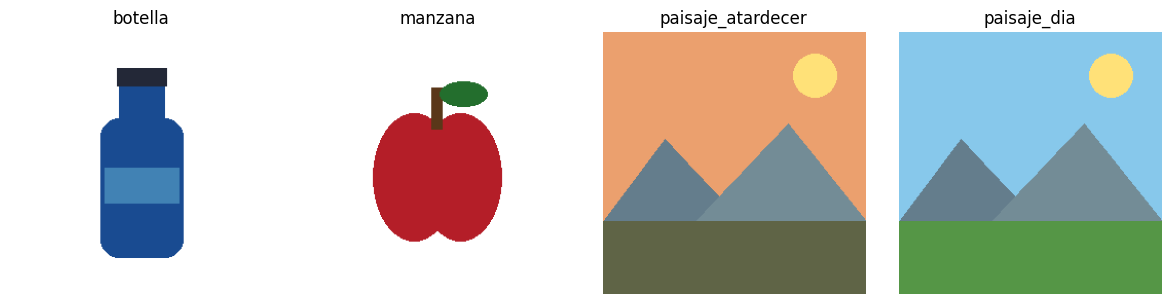

Objetos: 2 | Fondos: 2


In [2]:
TAMANO = (256, 256)
UMBRAL = 200
RADIO = 1.5

objetos = sorted(Path('data/objects').glob('*.png'))
fondos = sorted(Path('data/backgrounds').glob('*.png'))
assert objetos and fondos, 'Faltan las carpetas de imágenes. Revisar las instrucciones.'

def cargar_imagen(ruta):
    with Image.open(ruta) as imagen:
        return imagen.convert('RGB').resize(TAMANO)

fig, ejes = plt.subplots(1, 4, figsize=(12, 3))
for eje, ruta in zip(ejes, objetos + fondos):
    eje.imshow(cargar_imagen(ruta))
    eje.set_title(ruta.stem)
    eje.axis('off')
plt.tight_layout()
plt.show()
print('Objetos:', len(objetos), '| Fondos:', len(fondos))

### 2. Máscara y composición

Se convierte el objeto a escala de grises con Pillow. Como su fondo es blanco,
los píxeles con intensidad **menor que 200** se consideran parte del objeto.
La máscara binaria vale **255 en el objeto y 0 en el fondo**. Luego se suaviza
con un filtro gaussiano y se normaliza al intervalo **[0, 1]**, obteniendo valores
intermedios de alpha en los bordes.

La composición se calcula como:

$$\mathrm{resultado}=\alpha\,\mathrm{objeto}+(1-\alpha)\,\mathrm{fondo}.$$

Cuando alpha vale 1, se conserva el objeto; cuando vale 0, se muestra el fondo.
Los valores intermedios mezclan ambas imágenes.

Para operar con PyTorch, las imágenes se convierten a tensores `float32`, en el
intervalo **[0, 1]**, con orden **canales, alto, ancho**. La máscara tiene un canal
y se aplica a los tres canales de color. No se entrena ninguna red neuronal.

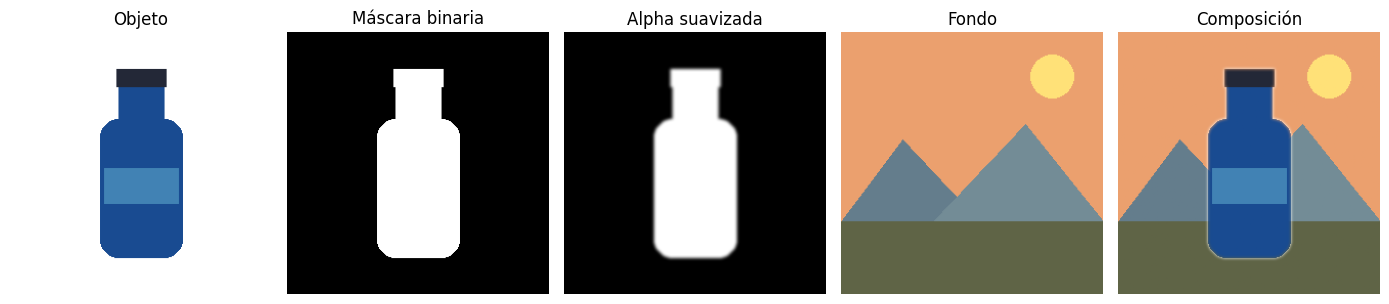

Alpha mínima: 0.0 | Alpha máxima: 1.0
Píxeles con alpha intermedia: 4014


In [3]:
def crear_mascara(imagen, umbral=UMBRAL, radio=RADIO):
    gris = np.array(imagen.convert('L'))
    binaria = (gris < umbral).astype(np.uint8) * 255
    mascara = Image.fromarray(binaria)
    suave = mascara.filter(ImageFilter.GaussianBlur(radius=radio))
    alpha = np.array(suave, dtype=np.float32) / 255.0
    return binaria, alpha

def convertir_tensor(imagen):
    matriz = np.array(imagen, dtype=np.float32) / 255.0
    return torch.from_numpy(matriz).permute(2, 0, 1)

objeto = cargar_imagen(objetos[0])
fondo = cargar_imagen(fondos[0])
binaria, alpha = crear_mascara(objeto)
objeto_t = convertir_tensor(objeto)
fondo_t = convertir_tensor(fondo)
alpha_t = torch.from_numpy(alpha).unsqueeze(0)
resultado = alpha_t * objeto_t + (1 - alpha_t) * fondo_t

fig, ejes = plt.subplots(1, 5, figsize=(14, 3))
paneles = [objeto, binaria, alpha, fondo, resultado.permute(1, 2, 0).numpy()]
titulos = ['Objeto', 'Máscara binaria', 'Alpha suavizada', 'Fondo', 'Composición']
for i, (eje, panel, titulo) in enumerate(zip(ejes, paneles, titulos)):
    if i in [1, 2]:
        eje.imshow(panel, cmap='gray', vmin=0, vmax=255 if i == 1 else 1)
    else:
        eje.imshow(panel)
    eje.set_title(titulo)
    eje.axis('off')
plt.tight_layout()
plt.show()
print('Alpha mínima:', alpha.min(), '| Alpha máxima:', alpha.max())
print('Píxeles con alpha intermedia:', np.sum((alpha > 0) & (alpha < 1)))

### 3. Dataset propio
`__len__` indica la cantidad de ejemplos y `__getitem__` prepara uno.
Se muestran las **cuatro combinaciones posibles** de los dos objetos y los dos
fondos. El emparejamiento es fijo para poder verificarlo; el `DataLoader`
mezcla el orden. La consigna permite, pero no exige, elegir el fondo al azar.

In [4]:
class ComposicionesDataset(Dataset):
    def __init__(self, objetos, fondos):
        self.objetos = objetos
        self.fondos = fondos

    def __len__(self):
        return len(self.objetos) * len(self.fondos)

    def __getitem__(self, indice):
        ruta_objeto = self.objetos[indice // len(self.fondos)]
        ruta_fondo = self.fondos[indice % len(self.fondos)]

        objeto = cargar_imagen(ruta_objeto)
        fondo = cargar_imagen(ruta_fondo)
        _, alpha = crear_mascara(objeto)

        objeto_t = convertir_tensor(objeto)
        fondo_t = convertir_tensor(fondo)
        alpha_t = torch.from_numpy(alpha).unsqueeze(0)
        compuesta = alpha_t * objeto_t + (1 - alpha_t) * fondo_t

        nombre = ruta_objeto.stem + ' / ' + ruta_fondo.stem
        return compuesta, alpha_t, nombre

dataset = ComposicionesDataset(objetos, fondos)
loader = DataLoader(dataset, batch_size=4, shuffle=True, num_workers=0)
imagenes, mascaras, nombres = next(iter(loader))

print('Ejemplos del Dataset:', len(dataset))
print('Lote de imágenes:', tuple(imagenes.shape), imagenes.dtype)
print('Lote de máscaras:', tuple(mascaras.shape), mascaras.dtype)
print('Rango del lote:', imagenes.min().item(), imagenes.max().item())

Ejemplos del Dataset: 4
Lote de imágenes: (4, 3, 256, 256) torch.float32
Lote de máscaras: (4, 1, 256, 256) torch.float32
Rango del lote: 0.09803921729326248 1.0


### 4. Lote de resultados
La fila superior muestra las composiciones. La inferior muestra sus máscaras
alpha. Blanco conserva el objeto, negro utiliza el fondo y gris mezcla ambos.

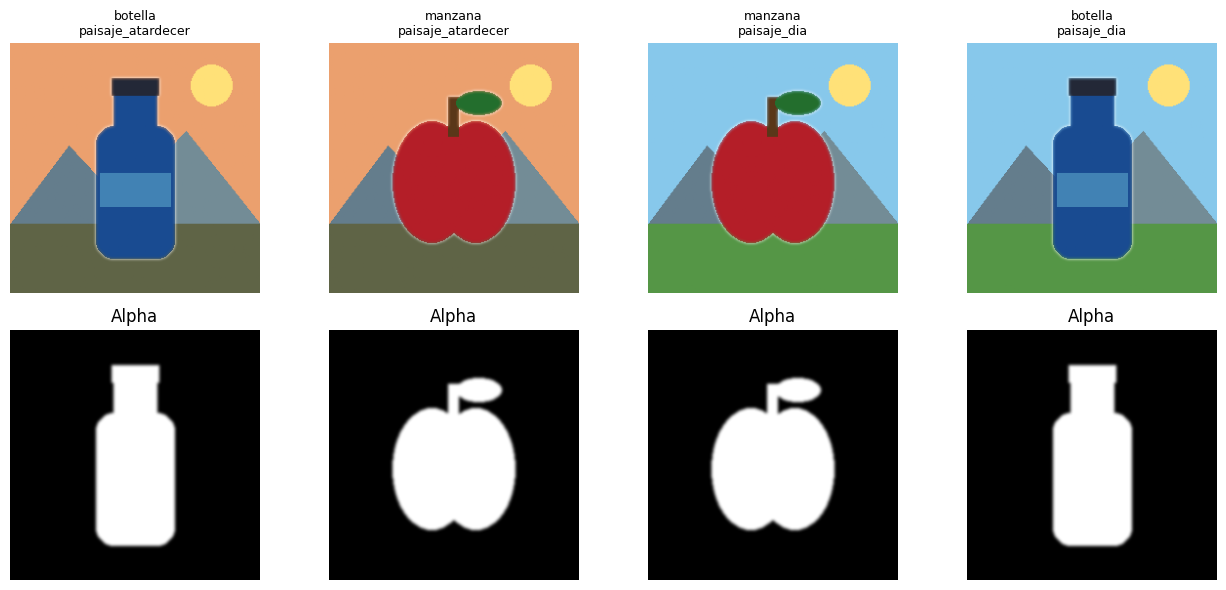

In [5]:
fig, ejes = plt.subplots(2, len(imagenes), figsize=(13, 6))
for i in range(len(imagenes)):
    ejes[0, i].imshow(imagenes[i].permute(1, 2, 0).numpy())
    ejes[0, i].set_title(nombres[i].replace(' / ', '\n'), fontsize=9)
    ejes[1, i].imshow(mascaras[i, 0].numpy(), cmap='gray', vmin=0, vmax=1)
    ejes[1, i].set_title('Alpha')
    ejes[0, i].axis('off')
    ejes[1, i].axis('off')
plt.tight_layout()
plt.show()

### 5. Comparación del suavizado
Se mantiene el mismo objeto y fondo para comparar una máscara sin suavizado
con otra de radio 1.5. El detalle ampliado permite observar la transición en el borde.

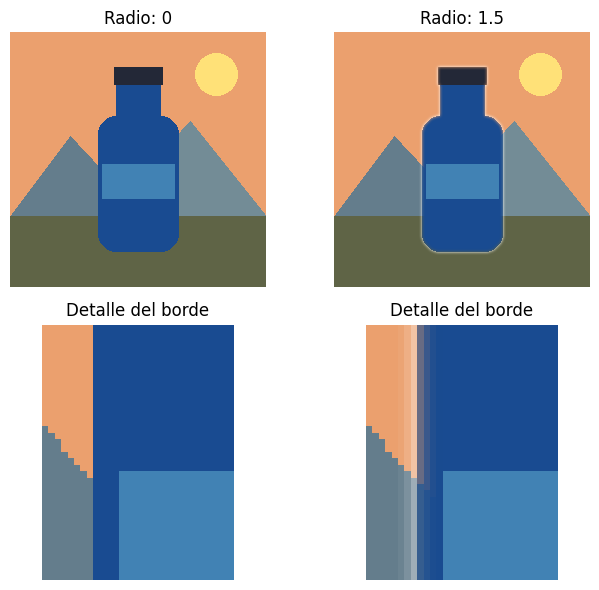

In [6]:
objeto = cargar_imagen(Path('data/objects/botella.png'))
fondo = cargar_imagen(fondos[0])
objeto_t = convertir_tensor(objeto)
fondo_t = convertir_tensor(fondo)

fig, ejes = plt.subplots(2, 2, figsize=(7, 6))
for columna, radio in enumerate([0, 1.5]):
    _, alpha = crear_mascara(objeto, radio=radio)
    alpha_t = torch.from_numpy(alpha).unsqueeze(0)
    salida = alpha_t * objeto_t + (1 - alpha_t) * fondo_t
    imagen = salida.permute(1, 2, 0).numpy()
    ejes[0, columna].imshow(imagen)
    ejes[0, columna].set_title('Radio: ' + str(radio))
    ejes[1, columna].imshow(imagen[110:150, 80:110], interpolation='nearest')
    ejes[1, columna].set_title('Detalle del borde')
    ejes[0, columna].axis('off')
    ejes[1, columna].axis('off')
plt.tight_layout()
plt.show()

### 6. Conclusiones
- La máscara por luminancia separa los dos objetos del fondo blanco en estas
  imágenes de prueba. Las cuatro composiciones conservan los objetos y cambian el fondo.
- El filtro gaussiano genera alpha intermedia y suaviza los bordes. También puede
  introducir un halo claro al mezclar píxeles del fondo blanco original; aumentar
  demasiado el radio hace perder definición.
- El `Dataset` reúne el procesamiento de cada ejemplo y el `DataLoader` entrega
  el lote de cuatro imágenes con forma `(4, 3, 256, 256)`.
- El método depende del contraste: un objeto blanco sobre fondo blanco podría
  desaparecer de la máscara. Tampoco resuelve transparencias ni fondos complejos.
  Para este ejercicio se eligieron entradas sencillas y un umbral fijo.

### Referencias
- Material de la materia: **Clase Nº 6 — Trabajo con Múltiples Imágenes
  (Aplicación con Bibliotecas TensorFlow y PyTorch)**.
- PyTorch: [Dataset y DataLoader](https://pytorch.org/tutorials/beginner/basics/data_tutorial.html).
- Pillow: [ImageFilter](https://pillow.readthedocs.io/en/stable/reference/ImageFilter.html).